First 5 rows :    Student_ID  Study_Hours  Attendance  Previous_Score  Assignments_Score  \
0         101          2.5        65.0            48.0               52.0   
1         102          4.0        78.0            61.0               68.0   
2         103          6.5        92.0            75.0               81.0   
3         104          1.5        55.0            42.0               45.0   
4         105          5.0        85.0            68.0               72.0   

   Sleep_Hours  Gender        Course  Final_Score  Pass  
0            6    Male        Python         50.0  Fail  
1            7  Female        Python         65.0  Pass  
2            8    Male  Data Science         82.0  Pass  
3            5  Female        Python         43.0  Fail  
4            7    Male  Data Science         74.0  Pass  
Shape of dataframe : (30, 10)
columns of dataframe : Index(['Student_ID', 'Study_Hours', 'Attendance', 'Previous_Score',
       'Assignments_Score', 'Sleep_Hours', 'Gender', 

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Accuracy: 0.0 %
DT Accuracy: 0.0 %
KNN Accuracy: 0.0 %


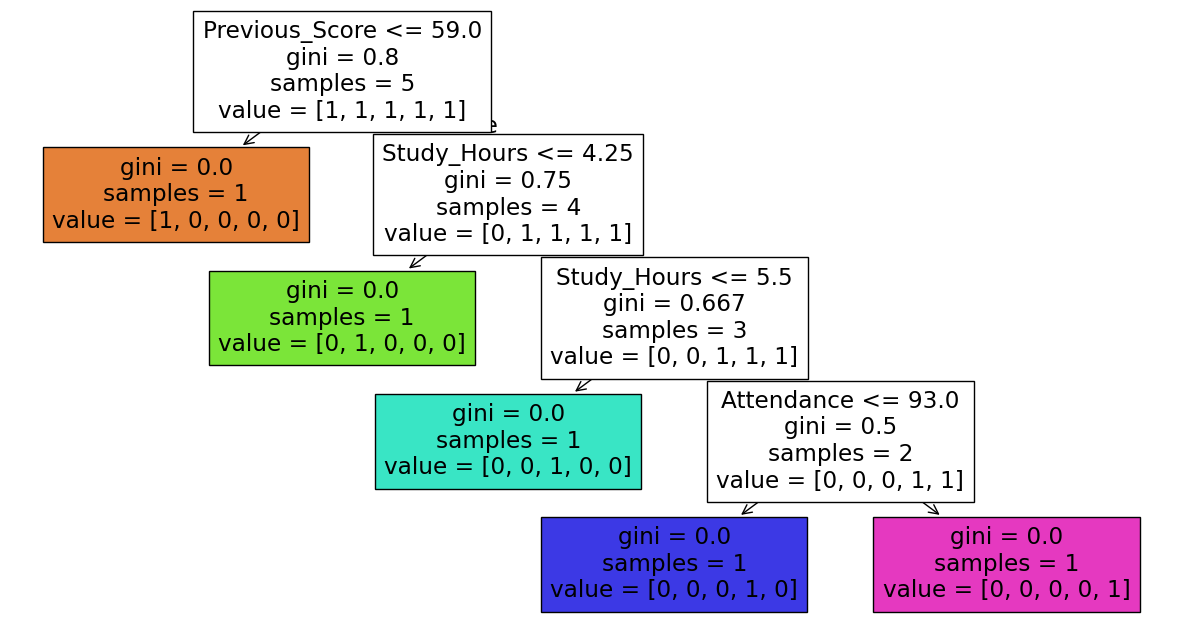

Max Depth 2
Training Accuracy: 60.0 %
Testing Accuracy: 0.0 %
Max Depth 5
Training Accuracy: 100.0 %
Testing Accuracy: 0.0 %
Max Depth 10
Training Accuracy: 100.0 %
Testing Accuracy: 0.0 %
K = 2
    Student_ID  Study_Hours  Final_Score  Cluster_K2
0          101     2.500000         50.0           1
1          102     4.000000         65.0           1
2          103     6.500000         82.0           0
3          104     1.500000         43.0           1
4          105     5.000000         74.0           0
5          106     3.000000         59.0           1
6          107     7.000000         90.0           0
7          108     4.500000         69.0           1
8          109     2.000000         48.0           1
9          110     8.000000         95.0           0
10         111     3.500000         62.0           1
11         112     5.500000         79.0           0
12         113     1.000000         39.0           1
13         114     6.000000         85.0           0
14        

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.cluster import KMeans
data = {
    "Student_ID": [101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130],

    "Study_Hours": [2.5,4.0,6.5,1.5,5.0,3.0,7.0,4.5,2.0,8.0,3.5,5.5,1.0,6.0,4.0,2.5,7.5,3.0,5.0,6.5,2.0,4.5,5.5,None,3.5,7.0,1.5,4.0,6.0,2.5],

    "Attendance": [65,78,92,55,85,70,95,80,60,98,72,88,50,90,75,62,94,68,82,91,None,79,87,73,69,96,54,77,89,64],

    "Previous_Score": [48,61,75,42,68,55,82,64,45,90,58,72,38,78,60,47,85,52,70,80,44,None,73,57,53,84,40,63,76,46],

    "Assignments_Score": [52,68,81,45,72,60,88,70,50,94,65,78,40,84,66,51,90,57,74,86,48,71,None,62,58,91,43,67,82,50],

    "Sleep_Hours": [6,7,8,5,7,6,8,7,5,9,6,8,5,7,6,5,8,6,7,8,5,7,8,6,6,9,5,7,8,6],

    "Gender": ["Male","Female","Male","Female","Male","Female","Male","Female","Male","Female",
               "Male","Female","Male","Female","Male","Female","Male","Female","Male","Female",
               "Male","Female","Male","Female","Male","Female","Male","Female","Male","Female"],

    "Course": ["Python","Python","Data Science","Python","Data Science","Web Development",
               "Data Science","Web Development","Python","Data Science","Web Development",
               "Python","Python","Data Science","Web Development","Python","Data Science",
               "Web Development","Python","Data Science","Python","Web Development",
               "Data Science","Python",None,"Data Science","Python","Web Development",
               "Data Science","Python"],

    "Final_Score": [50,65,82,43,74,59,90,69,48,95,62,79,39,85,64,49,92,55,73,87,46,68,78,60,56,91,None,66,84,51],

    "Pass": ["Fail","Pass","Pass","Fail","Pass","Fail","Pass","Pass","Fail","Pass",
             "Pass","Pass","Fail","Pass","Pass","Fail","Pass","Fail","Pass","Pass",
             "Fail","Pass","Pass","Pass","Fail","Pass","Fail","Pass","Pass","Fail"]
}

df=pd.DataFrame(data)
#part 1
print("First 5 rows :",df.head())
print("Shape of dataframe :",df.shape)
print("columns of dataframe :",df.columns)
print("Basic information of dataframe :",df.info())
print("Finding missing value : ",df.isnull())
df['Study_Hours']=df['Study_Hours'].fillna(df['Study_Hours'].mean())
print("Using Fill_na method : ",df)
df=df.dropna()
print("using dropna method : ",df)
print("Duplicate rows : ",df.duplicated())

#part 2
model=LabelEncoder()
df['Pass']=model.fit_transform(df['Pass'])
print("Labelled encoding :",df)
df=pd.get_dummies(df,columns=['Course'],dtype=int)
print("One_hot_encoding : ",df)

#Part 3
#Linearregression
X=df[['Study_Hours', 'Attendance', 'Previous_Score', 'Assignments_Score']]
Y=df['Final_Score']
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.8,random_state=42)
model=LinearRegression()
model.fit(X_train,Y_train)
predicted=model.predict(X_test)
result = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': predicted
})
print(result)
#polynomialregression
poly2 = PolynomialFeatures(degree=2)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)
model2 = LinearRegression()
model2.fit(X_train_poly2, Y_train)
predicted2 = model2.predict(X_test_poly2)
result2 = pd.DataFrame({
    "Actual": Y_test.values,
    "Predicted": predicted2
})
print("Polynomial Regression - Degree 2")
print(result2)

#Degree=3
poly3 = PolynomialFeatures(degree=3)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)
model3 = LinearRegression()
model3.fit(X_train_poly3, Y_train)
predicted3 = model3.predict(X_test_poly3)
result3 = pd.DataFrame({
    "Actual": Y_test.values,
    "Predicted": predicted3
})
print("Polynomial Regression - Degree 3")
print(result3)

#Part4
mae = mean_absolute_error(Y_test, predicted)
mse = mean_squared_error(Y_test, predicted)
rmse = mse**0.5
mae2 = mean_absolute_error(Y_test, predicted2)
mse2 = mean_squared_error(Y_test, predicted2)
rmse2 = mse2**0.5
mae3 = mean_absolute_error(Y_test, predicted3)
mse3 = mean_squared_error(Y_test, predicted3)
rmse3 = mse3**0.5
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Degree 2",
        "Polynomial Degree 3"],
    "MAE": [mae, mae2, mae3],
    "MSE": [mse, mse2, mse3],
    "RMSE": [rmse, rmse2, rmse3]
})
print(comparison)

#Part5
X = df[[
    "Study_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments_Score"
]]

y = df["Pass"]
y = y.map({
    "Pass": 1,
    "Fail": 0
})
#logistic regression
log_model = LogisticRegression()
log_model.fit(X_train, Y_train)
log_pred = log_model.predict(X_test)
log_accuracy = accuracy_score(Y_test, log_pred)
print("Logistic Regression Accuracy:",
      log_accuracy * 100, "%")


#Decisiontree
tree_model=DecisionTreeClassifier()
tree_model.fit(X_train, Y_train)
DT_pre=tree_model.predict(X_test)
DT_accuracy=accuracy_score(Y_test,DT_pre)
print("DT Accuracy:",DT_accuracy*100,"%")


#KNN
model=KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, Y_train)
KNN_pre=model.predict(X_test)
KNN_accuracy=accuracy_score(Y_test,KNN_pre)
print("KNN Accuracy:",DT_accuracy*100,"%")


#part 6
#decision tree visualization
plt.figure(figsize=(15, 8))
plot_tree(
    tree_model,
    feature_names=X.columns,
    filled=True
)
plt.show()

#part 7
#Depth=2
model2 = DecisionTreeClassifier(max_depth=2, random_state=42)
model2.fit(X_train, Y_train)

train_pred2 = model2.predict(X_train)
test_pred2 = model2.predict(X_test)

train_acc2 = accuracy_score(Y_train, train_pred2)
test_acc2 = accuracy_score(Y_test, test_pred2)

print("Max Depth 2")
print("Training Accuracy:", train_acc2 * 100, "%")
print("Testing Accuracy:", test_acc2 * 100, "%")

#Depth=5

model3 = DecisionTreeClassifier(max_depth=5, random_state=42)
model3.fit(X_train, Y_train)

train_pred3 = model3.predict(X_train)
test_pred3 = model3.predict(X_test)

train_acc3 = accuracy_score(Y_train, train_pred3)
test_acc3 = accuracy_score(Y_test, test_pred3)

print("Max Depth 5")
print("Training Accuracy:", train_acc3 * 100, "%")
print("Testing Accuracy:", test_acc3 * 100, "%")

#Depth=10
model4 = DecisionTreeClassifier(max_depth=10, random_state=42)
model4.fit(X_train, Y_train)

train_pred4 = model4.predict(X_train)
test_pred4= model4.predict(X_test)

train_acc4 = accuracy_score(Y_train, train_pred4)
test_acc4 = accuracy_score(Y_test, test_pred4)

print("Max Depth 10")
print("Training Accuracy:", train_acc4 * 100, "%")
print("Testing Accuracy:", test_acc4 * 100, "%")

#part 8
#Kmeans clustering
#CLUSTER 2
X = df[["Study_Hours", "Final_Score"]]
kmeans2 = KMeans(n_clusters=2, random_state=42, n_init=10)
df["Cluster_K2"] = kmeans2.fit_predict(X)
print("K = 2")
print(df[["Student_ID", "Study_Hours", "Final_Score", "Cluster_K2"]])

print("\nCluster 0:")
print(df[df["Cluster_K2"] == 0])

print("\nCluster 1:")
print(df[df["Cluster_K2"] == 1])

print("\nAverage of each cluster:")
print(df.groupby("Cluster_K2")[["Study_Hours", "Final_Score"]].mean())

#CLUSTER 3
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster_K3"] = kmeans3.fit_predict(X)

print("\nK = 3")
print(df[["Student_ID", "Study_Hours", "Final_Score", "Cluster_K3"]])

print("\nAverage of each cluster:")
print(df.groupby("Cluster_K3")[["Study_Hours", "Final_Score"]].mean())

#CLUSTER 4
kmeans4 = KMeans(n_clusters=4, random_state=42, n_init=10)

df["Cluster_K4"] = kmeans4.fit_predict(X)

print("\nK = 4")
print(df[["Student_ID", "Study_Hours", "Final_Score", "Cluster_K4"]])

print("\nAverage of each cluster:")
print(df.groupby("Cluster_K4")[["Study_Hours", "Final_Score"]].mean())







In [ ]:
import